# Projet Fil Rouge - indicateurs de naissance en France
### Mcharek, Marwa, 2026

## Data Cleaning

## 1. Importation des données

### Lecture du fichier Excel

In [1]:
import pandas as pd
# On importe pandas pour lire, nettoyer et analyser les données.

df = pd.read_excel(
    "../data/raw/naissances.xlsx",
    sheet_name=1,
    skiprows=5,
    header=[0, 1]
)
# On lit le fichier Excel naissances.xlsx.
# sheet_name=1 signifie qu’on lit la deuxième feuille du fichier.
# skiprows=5 permet d’ignorer les lignes de titre/description.
# header=[0, 1] indique que les noms de colonnes sont sur deux lignes.

new_columns = []
# On crée une liste vide pour stocker les nouveaux noms de colonnes.

for col in df.columns:
    # On parcourt chaque colonne du tableau.

    niveau_1 = str(col[0]).strip()
    # On récupère le premier niveau du nom de colonne, par exemple l’année 2012.

    niveau_2 = str(col[1]).strip()
    # On récupère le deuxième niveau, par exemple naissances totales.

    if "Unnamed" in niveau_1 and "Unnamed" in niveau_2:
        new_columns.append("a_supprimer")
        # Si les deux niveaux sont vides/inutiles, on marque la colonne à supprimer.

    elif "Unnamed" in niveau_1:
        new_columns.append(niveau_2)
        # Si le premier niveau est vide, on garde seulement le deuxième niveau.

    elif "Unnamed" in niveau_2:
        new_columns.append(niveau_1)
        # Si le deuxième niveau est vide, on garde seulement le premier niveau.

    else:
        new_columns.append(f"{niveau_1}_{niveau_2}")
        # Sinon, on combine les deux niveaux : année + type d’indicateur.

df.columns = new_columns
# On remplace les anciens noms de colonnes par les nouveaux noms propres.

df = df.drop(columns=["a_supprimer"], errors="ignore")
# On supprime les colonnes inutiles repérées plus haut.

df.columns = (
    df.columns
    .str.replace(" ", "_")
    .str.replace("'", "_")
    .str.lower()
)
# On nettoie les noms : espaces remplacés par _, apostrophes remplacées, tout en minuscules.


## Exploration initiale des données
### Aperçu du jeu de données

In [2]:
df.head()
# On affiche les 5 premières lignes pour vérifier le résultat.

,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
0,Auvergne - Rhône-Alpes,97162.0,96344.0,95854.0,95073.0,96683.0,95926.0,94586.0,93854.0,92364.0,...,89174.0,88514.0,86542.0,85873.0,87069.0,86382.0,84877.0,84219.0,78411.0,77821.0
1,Bourgogne - Franche-Comté,31467.0,31181.0,30706.0,30459.0,30447.0,30199.0,29532.0,29295.0,28553.0,...,26304.0,26086.0,25836.0,25632.0,25558.0,25314.0,24979.0,24758.0,23348.0,23160.0
2,Bretagne,36740.0,36457.0,35861.0,35559.0,35251.0,34971.0,33712.0,33445.0,32990.0,...,31518.0,31276.0,31238.0,30991.0,32088.0,31826.0,31261.0,30991.0,29113.0,28861.0
3,Centre - Val de Loire,30217.0,29917.0,29419.0,29167.0,29225.0,28984.0,27955.0,27705.0,27478.0,...,26055.0,25823.0,25506.0,25284.0,25582.0,25382.0,25375.0,25175.0,23129.0,22906.0
4,Corse,2995.0,2960.0,2920.0,2887.0,3022.0,2981.0,2873.0,2842.0,2922.0,...,2875.0,2848.0,2682.0,2662.0,2743.0,2722.0,2744.0,2720.0,2513.0,2487.0


### Dimensions du tableau

In [3]:
df.shape
# Affiche le nombre de lignes et de colonnes.

(119, 25)

### Types des variables

In [4]:
df.info()
# Affiche les types des colonnes et les valeurs non manquantes.

<class 'pandas.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   zone_géographique         118 non-null    str    
 1   2012_naissances_totales   117 non-null    float64
 2   2012_naissances_vivantes  117 non-null    float64
 3   2013_naissances_totales   117 non-null    float64
 4   2013_naissances_vivantes  117 non-null    float64
 5   2014_naissances_totales   117 non-null    float64
 6   2014_naissances_vivantes  117 non-null    float64
 7   2015_naissances_totales   117 non-null    float64
 8   2015_naissances_vivantes  117 non-null    float64
 9   2016_naissances_totales   117 non-null    float64
 10  2016_naissances_vivantes  117 non-null    float64
 11  2017_naissances_totales   117 non-null    object 
 12  2017_naissances_vivantes  117 non-null    object 
 13  2018_naissances_totales   117 non-null    float64
 14  2018_naissances_vivan

## Conversion des types de données

### Conversion des variables 2017 en numérique

In [5]:
# Conversion des colonnes 2017 en numérique.
# Ces colonnes avaient été importées en type object.
df["2017_naissances_totales"] = pd.to_numeric(
    df["2017_naissances_totales"],
    errors="coerce"
)

df["2017_naissances_vivantes"] = pd.to_numeric(
    df["2017_naissances_vivantes"],
    errors="coerce"
)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   zone_géographique         118 non-null    str    
 1   2012_naissances_totales   117 non-null    float64
 2   2012_naissances_vivantes  117 non-null    float64
 3   2013_naissances_totales   117 non-null    float64
 4   2013_naissances_vivantes  117 non-null    float64
 5   2014_naissances_totales   117 non-null    float64
 6   2014_naissances_vivantes  117 non-null    float64
 7   2015_naissances_totales   117 non-null    float64
 8   2015_naissances_vivantes  117 non-null    float64
 9   2016_naissances_totales   117 non-null    float64
 10  2016_naissances_vivantes  117 non-null    float64
 11  2017_naissances_totales   116 non-null    float64
 12  2017_naissances_vivantes  116 non-null    float64
 13  2018_naissances_totales   117 non-null    float64
 14  2018_naissances_vivan

### Recherche des valeurs manquantes

In [7]:
df.isna().sum()
# Compte les valeurs manquantes colonne par colonne.

zone_géographique           1
2012_naissances_totales     2
2012_naissances_vivantes    2
2013_naissances_totales     2
2013_naissances_vivantes    2
2014_naissances_totales     2
2014_naissances_vivantes    2
2015_naissances_totales     2
2015_naissances_vivantes    2
2016_naissances_totales     2
2016_naissances_vivantes    2
2017_naissances_totales     3
2017_naissances_vivantes    3
2018_naissances_totales     2
2018_naissances_vivantes    2
2019_naissances_totales     2
2019_naissances_vivantes    2
2020_naissances_totales     2
2020_naissances_vivantes    2
2021_naissances_totales     2
2021_naissances_vivantes    2
2022_naissances_totales     2
2022_naissances_vivantes    2
2023_naissances_totales     2
2023_naissances_vivantes    2
dtype: int64

### Identification des lignes problématiques

In [8]:
df[df.isna().any(axis=1)]
# Affiche uniquement les lignes contenant au moins une valeur manquante.
# any(axis=1) signifie :
# "au moins une cellule vide sur la ligne".

,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
14,Guadeloupe,5142.0,5057.0,5058.0,4972.0,4866.0,4787.0,4603.0,4498.0,4537.0,...,4506.0,4438.0,4666.0,4578.0,4298.0,4217.0,4089.0,4014.0,3914.0,3845.0
117,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
118,"**En 2017, les données du PMSI sont incomplète...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
df.tail()
# Affiche les 5 dernières lignes du tableau.
# Permet de vérifier que les lignes 117 et 118
# sont bien les lignes de commentaire du fichier.

,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
114,Seine-Saint-Denis,28763.0,28447.0,28736.0,28426.0,29619.0,29276.0,29556.0,29235.0,29421.0,...,28579.0,28312.0,28078.0,27775.0,26554.0,26282.0,26527.0,26258.0,25320.0,25064.0
115,Val-de-Marne,20999.0,20793.0,20731.0,20548.0,21588.0,21367.0,21082.0,20904.0,20922.0,...,20733.0,20539.0,20009.0,19835.0,19740.0,19570.0,19101.0,18951.0,17818.0,17654.0
116,Val-d'Oise,19510.0,19335.0,19507.0,19318.0,19695.0,19483.0,19616.0,19394.0,19671.0,...,19805.0,19617.0,19148.0,18963.0,19256.0,19076.0,19173.0,18994.0,17970.0,17764.0
117,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
118,"**En 2017, les données du PMSI sont incomplète...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Suppression des lignes parasites

### Identification des notes PMSI

### Suppression des lignes hors données

In [10]:
df = df.iloc[:-2]
# On supprime les 2 dernières lignes :
# - ligne vide
# - note PMSI

## 5. Validation du nettoyage

### Vérification des dimensions finales

In [11]:
df.shape

# Vérifie le nombre de lignes et de colonnes.

(117, 25)

### Vérification des valeurs manquantes restantes

In [12]:
df.isna().sum()

# Vérifie les valeurs manquantes après nettoyage.

zone_géographique           0
2012_naissances_totales     0
2012_naissances_vivantes    0
2013_naissances_totales     0
2013_naissances_vivantes    0
2014_naissances_totales     0
2014_naissances_vivantes    0
2015_naissances_totales     0
2015_naissances_vivantes    0
2016_naissances_totales     0
2016_naissances_vivantes    0
2017_naissances_totales     1
2017_naissances_vivantes    1
2018_naissances_totales     0
2018_naissances_vivantes    0
2019_naissances_totales     0
2019_naissances_vivantes    0
2020_naissances_totales     0
2020_naissances_vivantes    0
2021_naissances_totales     0
2021_naissances_vivantes    0
2022_naissances_totales     0
2022_naissances_vivantes    0
2023_naissances_totales     0
2023_naissances_vivantes    0
dtype: int64

In [13]:
df.tail()
# Vérification finale du DataFrame après nettoyage.
# Les lignes de commentaire ont été supprimées.

,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
112,Essonne,18615.0,18396.0,18599.0,18429.0,18997.0,18816.0,19128.0,18935.0,18747.0,...,18585.0,18397.0,18482.0,18286.0,18538.0,18353.0,18385.0,18223.0,17263.0,17084.0
113,Hauts-de-Seine,24899.0,24647.0,24904.0,24689.0,25015.0,24794.0,24360.0,24149.0,24370.0,...,22905.0,22717.0,21908.0,21716.0,22010.0,21838.0,21079.0,20896.0,19863.0,19713.0
114,Seine-Saint-Denis,28763.0,28447.0,28736.0,28426.0,29619.0,29276.0,29556.0,29235.0,29421.0,...,28579.0,28312.0,28078.0,27775.0,26554.0,26282.0,26527.0,26258.0,25320.0,25064.0
115,Val-de-Marne,20999.0,20793.0,20731.0,20548.0,21588.0,21367.0,21082.0,20904.0,20922.0,...,20733.0,20539.0,20009.0,19835.0,19740.0,19570.0,19101.0,18951.0,17818.0,17654.0
116,Val-d'Oise,19510.0,19335.0,19507.0,19318.0,19695.0,19483.0,19616.0,19394.0,19671.0,...,19805.0,19617.0,19148.0,18963.0,19256.0,19076.0,19173.0,18994.0,17970.0,17764.0


In [14]:
# Une valeur manquante subsiste pour l'année 2017.
# Cela est cohérent avec la note du fichier PMSI indiquant
# que les données 2017 sont incomplètes.

### Résumé statistique

In [15]:
df.describe()  # Permet d'obtenir un résumé statistique des données numériques :
               # count = nombre de valeurs
               # mean = moyenne
               # std = écart-type
               # min / max = valeurs extrêmes
               # 25%, 50%, 75% = quartiles

,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,2016_naissances_vivantes,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
count,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,...,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000
mean,28080.487179,27822.709402,27776.461538,27528.641026,27747.700855,27505.111111,27067.692308,26829.290598,26565.213675,26331.333333,...,25461.641026,25247.726496,24867.487179,24648.888889,25037.487179,24817.358974,24526.914530,24313.179487,22801.589744,22602.555556
std,106339.883568,105368.273496,105237.215813,104303.976724,105159.236033,104243.339245,102525.758722,101628.538126,100615.564339,99734.252390,...,96398.305541,95593.735526,94139.719560,93317.924327,94691.447589,93865.129554,92753.382408,91950.933818,86199.378033,85451.016940
min,701.000000,699.000000,654.000000,653.000000,660.000000,652.000000,694.000000,685.000000,662.000000,659.000000,...,584.000000,580.000000,518.000000,513.000000,611.000000,609.000000,587.000000,581.000000,557.000000,553.000000
25%,3527.000000,3498.000000,3469.000000,3442.000000,3382.000000,3355.000000,3232.000000,3208.000000,3210.000000,3187.000000,...,2982.000000,2965.000000,2942.000000,2918.000000,2940.000000,2915.000000,2910.000000,2889.000000,2690.000000,2670.000000
50%,6809.000000,6755.000000,6710.000000,6648.000000,6688.000000,6643.000000,6561.000000,6497.000000,6384.000000,6329.000000,...,5967.000000,5931.000000,5971.000000,5924.000000,6002.000000,5949.000000,5828.000000,5778.000000,5405.000000,5372.000000
75%,16470.000000,16328.000000,16432.000000,16288.000000,16776.000000,16629.000000,16396.000000,16267.000000,16138.000000,16015.000000,...,15716.000000,15588.000000,15404.000000,15269.000000,15435.000000,15304.000000,15162.000000,15022.000000,14155.000000,14046.000000
max,830758.000000,823085.000000,821598.000000,814216.000000,820800.000000,813583.000000,801271.000000,794160.000000,786629.000000,779655.000000,...,754509.000000,748121.000000,736867.000000,730337.000000,742341.000000,735760.000000,727143.000000,720752.000000,676380.000000,670434.000000


## 2. Sauvegarde des données nettoyées

In [16]:
df.to_csv(
    "../data/processed/naissances_clean.csv",
    index=False
)

# Sauvegarde le DataFrame nettoyé dans le dossier processed.
# index=False évite d'ajouter une colonne d'index inutile.

## Structuration géographique des données

### Analyse de la structure géographique

Avant de séparer les données, j'examine les valeurs de la colonne
`zone_géographique` afin d'identifier les différents niveaux géographiques
présents dans le fichier.

In [17]:
df["zone_géographique"].tolist()

['Auvergne -  Rhône-Alpes',
 'Bourgogne -  Franche-Comté',
 'Bretagne',
 'Centre -  Val de Loire',
 'Corse',
 'Grand Est',
 'Hauts-de-France',
 'Ile-de-France',
 'Normandie',
 'Nouvelle-Aquitaine',
 'Occitanie',
 'Pays de la Loire',
 "Provence - Alpes - Côte d'Azur",
 'Total métropole',
 'Guadeloupe',
 'Guyane',
 'La Réunion',
 'Martinique',
 'Mayotte',
 'Total DROM',
 'Total France entière',
 'Ain',
 'Aisne',
 'Allier',
 'Alpes-de-Haute-Provence',
 'Hautes-Alpes',
 'Alpes-Maritimes',
 'Ardèche',
 'Ardennes',
 'Ariège',
 'Aube',
 'Aude',
 'Aveyron',
 'Bouches-du-Rhône',
 'Calvados',
 'Cantal',
 'Charente',
 'Charente-Maritime',
 'Cher',
 'Corrèze',
 "Côte-d'Or",
 "Côtes-d'Armor",
 'Creuse',
 'Dordogne',
 'Doubs',
 'Drôme',
 'Eure',
 'Eure-et-Loir',
 'Finistère',
 'Corse-du-Sud',
 'Haute-Corse',
 'Gard',
 'Haute-Garonne',
 'Gers',
 'Gironde',
 'Hérault',
 'Ille-et-Vilaine',
 'Indre',
 'Indre-et-Loire',
 'Isère',
 'Jura',
 'Landes',
 'Loir-et-Cher',
 'Loire',
 'Haute-Loire',
 'Loire-Atla

### Observation

La colonne contient :
- les régions françaises ;
- les départements ;
- les DROM ;
- des lignes de synthèse (Total métropole, Total DROM, Total France entière).

Une séparation des données est donc nécessaire pour faciliter les analyses.

### Création du DataFrame France entière

In [18]:
# Création du DataFrame France
df_france = df[
    df["zone_géographique"] == "Total France entière"
]

# Conserve uniquement la ligne correspondant à la France entière.
df_france["zone_géographique"].tolist()

['Total France entière']

### Création du DataFrame Régions

In [19]:
# Création du DataFrame Régions
regions = [
    "Auvergne -  Rhône-Alpes",
    "Bourgogne -  Franche-Comté",
    "Bretagne",
    "Centre -  Val de Loire",
    "Corse",
    "Grand Est",
    "Hauts-de-France",
    "Ile-de-France",
    "Normandie",
    "Nouvelle-Aquitaine",
    "Occitanie",
    "Pays de la Loire",
    "Provence - Alpes - Côte d'Azur",
    "Guadeloupe",
    "Guyane",
    "La Réunion",
    "Martinique",
    "Mayotte"
]

df_regions = df[
    df["zone_géographique"].isin(regions)
]

# Conserve uniquement les régions.# Création du DataFrame France
df_regions["zone_géographique"].tolist()

['Auvergne -  Rhône-Alpes',
 'Bourgogne -  Franche-Comté',
 'Bretagne',
 'Centre -  Val de Loire',
 'Corse',
 'Grand Est',
 'Hauts-de-France',
 'Ile-de-France',
 'Normandie',
 'Nouvelle-Aquitaine',
 'Occitanie',
 'Pays de la Loire',
 "Provence - Alpes - Côte d'Azur",
 'Guadeloupe',
 'Guyane',
 'La Réunion',
 'Martinique',
 'Mayotte']

### Création du DataFrame Départements

In [20]:
# Création du DataFrame Départements
df_departements = df[
    ~df["zone_géographique"].isin(regions)
]

# Exclut les régions.

In [21]:
df_departements = df_departements[
    ~df_departements["zone_géographique"].isin(
        [
            "Total métropole",
            "Total DROM",
            "Total France entière"
        ]
    )
]
df_departements["zone_géographique"].tolist()

['Ain',
 'Aisne',
 'Allier',
 'Alpes-de-Haute-Provence',
 'Hautes-Alpes',
 'Alpes-Maritimes',
 'Ardèche',
 'Ardennes',
 'Ariège',
 'Aube',
 'Aude',
 'Aveyron',
 'Bouches-du-Rhône',
 'Calvados',
 'Cantal',
 'Charente',
 'Charente-Maritime',
 'Cher',
 'Corrèze',
 "Côte-d'Or",
 "Côtes-d'Armor",
 'Creuse',
 'Dordogne',
 'Doubs',
 'Drôme',
 'Eure',
 'Eure-et-Loir',
 'Finistère',
 'Corse-du-Sud',
 'Haute-Corse',
 'Gard',
 'Haute-Garonne',
 'Gers',
 'Gironde',
 'Hérault',
 'Ille-et-Vilaine',
 'Indre',
 'Indre-et-Loire',
 'Isère',
 'Jura',
 'Landes',
 'Loir-et-Cher',
 'Loire',
 'Haute-Loire',
 'Loire-Atlantique',
 'Loiret',
 'Lot',
 'Lot-et-Garonne',
 'Lozère',
 'Maine-et-Loire',
 'Manche',
 'Marne',
 'Haute-Marne',
 'Mayenne',
 'Meurthe-et-Moselle',
 'Meuse',
 'Morbihan',
 'Moselle',
 'Nièvre',
 'Nord',
 'Oise',
 'Orne',
 'Pas-de-Calais',
 'Puy-de-Dôme',
 'Pyrénées-Atlantiques',
 'Hautes-Pyrénées',
 'Pyrénées-Orientales',
 'Bas-Rhin',
 'Haut-Rhin',
 'Rhône',
 'Haute-Saône',
 'Saône-et-Loire',

### Contrôle des jeux de données créés

In [22]:
# =====================================================
# Structuration géographique des données
# =====================================================

# Les données contiennent :
# - une ligne France entière
# - les régions
# - les départements
#
# Je sépare ces niveaux géographiques
# afin de faciliter les futures analyses
# et visualisations.
print("France :", df_france.shape)
print("Régions :", df_regions.shape)
print("Départements :", df_departements.shape)

France : (1, 25)
Régions : (18, 25)
Départements : (96, 25)


## Sauvegarde des données nettoyées

In [23]:
df_france.to_csv("../data/processed/naissances_france.csv", index=False)

df_regions.to_csv("../data/processed/naissances_regions.csv", index=False)

df_departements.to_csv("../data/processed/naissances_departements.csv", index=False)

In [24]:
# Vérification finale

print("France")
display(df_france.head())

print("Régions")
display(df_regions.head())

print("Départements")
display(df_departements.head())

France


,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
20,Total France entière,830758.0,823085.0,821598.0,814216.0,820800.0,813583.0,801271.0,794160.0,786629.0,...,754509.0,748121.0,736867.0,730337.0,742341.0,735760.0,727143.0,720752.0,676380.0,670434.0


Régions


,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
0,Auvergne - Rhône-Alpes,97162.0,96344.0,95854.0,95073.0,96683.0,95926.0,94586.0,93854.0,92364.0,...,89174.0,88514.0,86542.0,85873.0,87069.0,86382.0,84877.0,84219.0,78411.0,77821.0
1,Bourgogne - Franche-Comté,31467.0,31181.0,30706.0,30459.0,30447.0,30199.0,29532.0,29295.0,28553.0,...,26304.0,26086.0,25836.0,25632.0,25558.0,25314.0,24979.0,24758.0,23348.0,23160.0
2,Bretagne,36740.0,36457.0,35861.0,35559.0,35251.0,34971.0,33712.0,33445.0,32990.0,...,31518.0,31276.0,31238.0,30991.0,32088.0,31826.0,31261.0,30991.0,29113.0,28861.0
3,Centre - Val de Loire,30217.0,29917.0,29419.0,29167.0,29225.0,28984.0,27955.0,27705.0,27478.0,...,26055.0,25823.0,25506.0,25284.0,25582.0,25382.0,25375.0,25175.0,23129.0,22906.0
4,Corse,2995.0,2960.0,2920.0,2887.0,3022.0,2981.0,2873.0,2842.0,2922.0,...,2875.0,2848.0,2682.0,2662.0,2743.0,2722.0,2744.0,2720.0,2513.0,2487.0


Départements


,zone_géographique,2012_naissances_totales,2012_naissances_vivantes,2013_naissances_totales,2013_naissances_vivantes,2014_naissances_totales,2014_naissances_vivantes,2015_naissances_totales,2015_naissances_vivantes,2016_naissances_totales,...,2019_naissances_totales,2019_naissances_vivantes,2020_naissances_totales,2020_naissances_vivantes,2021_naissances_totales,2021_naissances_vivantes,2022_naissances_totales,2022_naissances_vivantes,2023_naissances_totales,2023_naissances_vivantes
21,Ain,7295.0,7231.0,7371.0,7316.0,7419.0,7367.0,7065.0,7008.0,7190.0,...,6946.0,6901.0,6877.0,6817.0,7044.0,6993.0,6891.0,6842.0,6326.0,6293.0
22,Aisne,6809.0,6748.0,6633.0,6574.0,6484.0,6430.0,6265.0,6215.0,5871.0,...,5464.0,5406.0,5374.0,5338.0,5374.0,5333.0,5416.0,5362.0,5139.0,5081.0
23,Allier,3303.0,3275.0,3217.0,3192.0,3168.0,3145.0,3031.0,3000.0,3028.0,...,2788.0,2765.0,2621.0,2592.0,2784.0,2763.0,2644.0,2619.0,2494.0,2476.0
24,Alpes-de-Haute-Provence,1542.0,1530.0,1611.0,1600.0,1528.0,1503.0,1486.0,1468.0,1464.0,...,1357.0,1346.0,1315.0,1303.0,1422.0,1415.0,1352.0,1347.0,1270.0,1256.0
25,Hautes-Alpes,1456.0,1438.0,1422.0,1408.0,1406.0,1391.0,1351.0,1340.0,1316.0,...,1249.0,1240.0,1188.0,1172.0,1277.0,1261.0,1249.0,1242.0,1089.0,1083.0


# 3. Visualisation des données

Cette partie présente plusieurs techniques de visualisation complémentaires.  
Le choix de chaque graphique dépend de la question étudiée :

- **courbe Matplotlib** pour analyser une évolution nationale ;
- **Treemap Plotly** pour comparer la contribution des régions ;
- **Area chart Plotly** pour suivre l'évolution de l'Île-de-France ;
- **Heatmap Seaborn** pour comparer simultanément les régions et les années ;
- **barres horizontales Plotly** pour établir un classement départemental.

Cette diversité permet de montrer la maîtrise de visualisations statiques et interactives, tout en préparant leur future intégration dans Streamlit.


In [25]:
# Bibliothèques nécessaires pour l'ensemble de la partie visualisation

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from matplotlib.ticker import FuncFormatter


## 3.1 Évolution des naissances en France entière — courbe Matplotlib

### Choix de la technique

Une **courbe chronologique** est adaptée pour représenter une variable mesurée chaque année.  
Matplotlib est conservé ici afin de montrer la maîtrise d'une bibliothèque classique de visualisation Python.

La préparation transforme les colonnes annuelles du DataFrame en un tableau au **format long**, plus lisible et plus facile à réutiliser ensuite dans Streamlit.


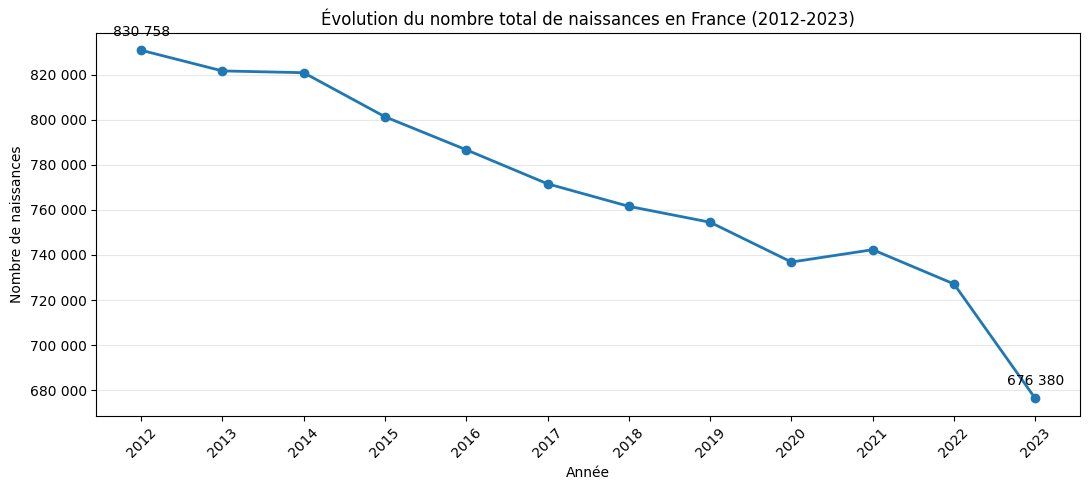

Variation entre 2012 et 2023 : -18.6 %


In [26]:
# Sélection automatique des colonnes contenant les naissances totales
colonnes_france = sorted(
    [col for col in df_france.columns if col.endswith("_naissances_totales")],
    key=lambda col: int(col.split("_")[0])
)

# Construction d'un DataFrame au format long
evolution_france = pd.DataFrame({
    "Année": [int(col.split("_")[0]) for col in colonnes_france],
    "Naissances": [
        pd.to_numeric(df_france[col].iloc[0], errors="coerce")
        for col in colonnes_france
    ]
}).dropna()

# Calcul de l'évolution entre la première et la dernière année
variation_france = (
    (evolution_france["Naissances"].iloc[-1] /
     evolution_france["Naissances"].iloc[0]) - 1
) * 100

# Création du graphique
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    evolution_france["Année"],
    evolution_france["Naissances"],
    marker="o",
    linewidth=2
)

# Mise en évidence de la première et de la dernière valeur
ax.annotate(
    f'{evolution_france["Naissances"].iloc[0]:,.0f}'.replace(",", " "),
    (evolution_france["Année"].iloc[0], evolution_france["Naissances"].iloc[0]),
    xytext=(0, 10),
    textcoords="offset points",
    ha="center"
)

ax.annotate(
    f'{evolution_france["Naissances"].iloc[-1]:,.0f}'.replace(",", " "),
    (evolution_france["Année"].iloc[-1], evolution_france["Naissances"].iloc[-1]),
    xytext=(0, 10),
    textcoords="offset points",
    ha="center"
)

ax.set_title("Évolution du nombre total de naissances en France (2012-2023)")
ax.set_xlabel("Année")
ax.set_ylabel("Nombre de naissances")
ax.set_xticks(evolution_france["Année"])
ax.tick_params(axis="x", rotation=45)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda valeur, position: f"{valeur:,.0f}".replace(",", " "))
)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Variation entre 2012 et 2023 : {variation_france:.1f} %")


### Interprétation

La courbe met en évidence une **diminution globale du nombre de naissances en France entre 2012 et 2023**.  
La baisse est presque continue, malgré une légère remontée autour de 2021. Le niveau observé en 2023 est le plus faible de la période représentée.

Le pourcentage calculé sous le graphique quantifie cette évolution entre la première et la dernière année. Cette tendance nationale constitue le contexte général pour l'analyse des différences régionales et départementales.


## 3.2 Répartition des naissances par région en 2023 — Treemap Plotly

### Choix de la technique

Le **Treemap** représente chaque région par un rectangle dont la surface est proportionnelle au nombre de naissances.  
Cette visualisation met immédiatement en évidence le poids relatif de chaque territoire et offre une alternative plus moderne à un graphique en barres classique.

L'interactivité de Plotly permet d'afficher les valeurs exactes au survol.


In [27]:
# Préparation des données régionales
treemap_regions = (
    df_regions[["zone_géographique", "2023_naissances_totales"]]
    .copy()
    .rename(columns={
        "zone_géographique": "Région",
        "2023_naissances_totales": "Naissances"
    })
)

treemap_regions["Naissances"] = pd.to_numeric(
    treemap_regions["Naissances"],
    errors="coerce"
)

treemap_regions = treemap_regions.dropna().sort_values(
    "Naissances",
    ascending=False
)

# Création du Treemap interactif
fig = px.treemap(
    treemap_regions,
    path=[px.Constant("France"), "Région"],
    values="Naissances",
    color="Naissances",
    title="Répartition des naissances par région en 2023"
)

fig.update_traces(
    texttemplate="<b>%{label}</b><br>%{value:,.0f}",
    hovertemplate="<b>%{label}</b><br>Naissances : %{value:,.0f}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    margin=dict(t=60, l=10, r=10, b=10)
)

fig.show()


### Interprétation

L'Île-de-France occupe la plus grande surface du Treemap : elle concentre le nombre de naissances le plus élevé en 2023.  
Les régions Auvergne-Rhône-Alpes et Hauts-de-France occupent également une place importante.

À l'inverse, la Corse et plusieurs territoires ultramarins présentent des surfaces plus petites. Ces écarts décrivent surtout des différences de volume démographique ; ils ne mesurent pas à eux seuls la fécondité ou le risque périnatal.


## 3.3 Évolution des naissances en Île-de-France — Area chart Plotly

### Choix de la technique

Un **graphique en aire** conserve la lecture chronologique d'une courbe tout en mettant davantage en évidence l'amplitude des variations.  
Plotly rend le graphique interactif : la valeur exacte de chaque année apparaît au survol.

La sélection de la région et des colonnes est automatisée afin d'éviter d'écrire manuellement chaque année.


In [28]:
# Recherche de la ligne correspondant à l'Île-de-France
idf = df_regions[
    df_regions["zone_géographique"]
    .astype(str)
    .str.replace("Î", "I", regex=False)
    .str.contains("Ile-de-France", case=False, na=False)
].copy()

if idf.empty:
    raise ValueError("La ligne correspondant à l'Île-de-France n'a pas été trouvée.")

# Réutilisation des colonnes annuelles détectées automatiquement
colonnes_idf = sorted(
    [col for col in df_regions.columns if col.endswith("_naissances_totales")],
    key=lambda col: int(col.split("_")[0])
)

evolution_idf = pd.DataFrame({
    "Année": [int(col.split("_")[0]) for col in colonnes_idf],
    "Naissances": [
        pd.to_numeric(idf[col].iloc[0], errors="coerce")
        for col in colonnes_idf
    ]
}).dropna()

# Création du graphique en aire
fig = px.area(
    evolution_idf,
    x="Année",
    y="Naissances",
    markers=True,
    title="Évolution des naissances en Île-de-France (2012-2023)"
)

fig.update_traces(
    hovertemplate="Année : %{x}<br>Naissances : %{y:,.0f}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Année",
    yaxis_title="Nombre de naissances",
    hovermode="x unified"
)

fig.update_yaxes(tickformat=",")
fig.show()


### Interprétation

Après un niveau élevé au début de la période et un pic autour de 2014, le nombre de naissances en Île-de-France diminue progressivement.  
La baisse devient particulièrement visible à partir de 2020 et le minimum de la série est atteint en 2023.

Cette évolution est cohérente avec la tendance nationale, même si le niveau francilien reste nettement supérieur à celui des autres régions.


## 3.4 Naissances par région et par année — Heatmap Seaborn

### Choix de la technique

La **Heatmap** permet de comparer deux dimensions en même temps :

- les régions sur l'axe vertical ;
- les années sur l'axe horizontal ;
- l'intensité de la couleur pour représenter le nombre de naissances.

Cette technique est particulièrement utile pour repérer rapidement les régions à forts volumes et l'évolution générale au cours du temps.


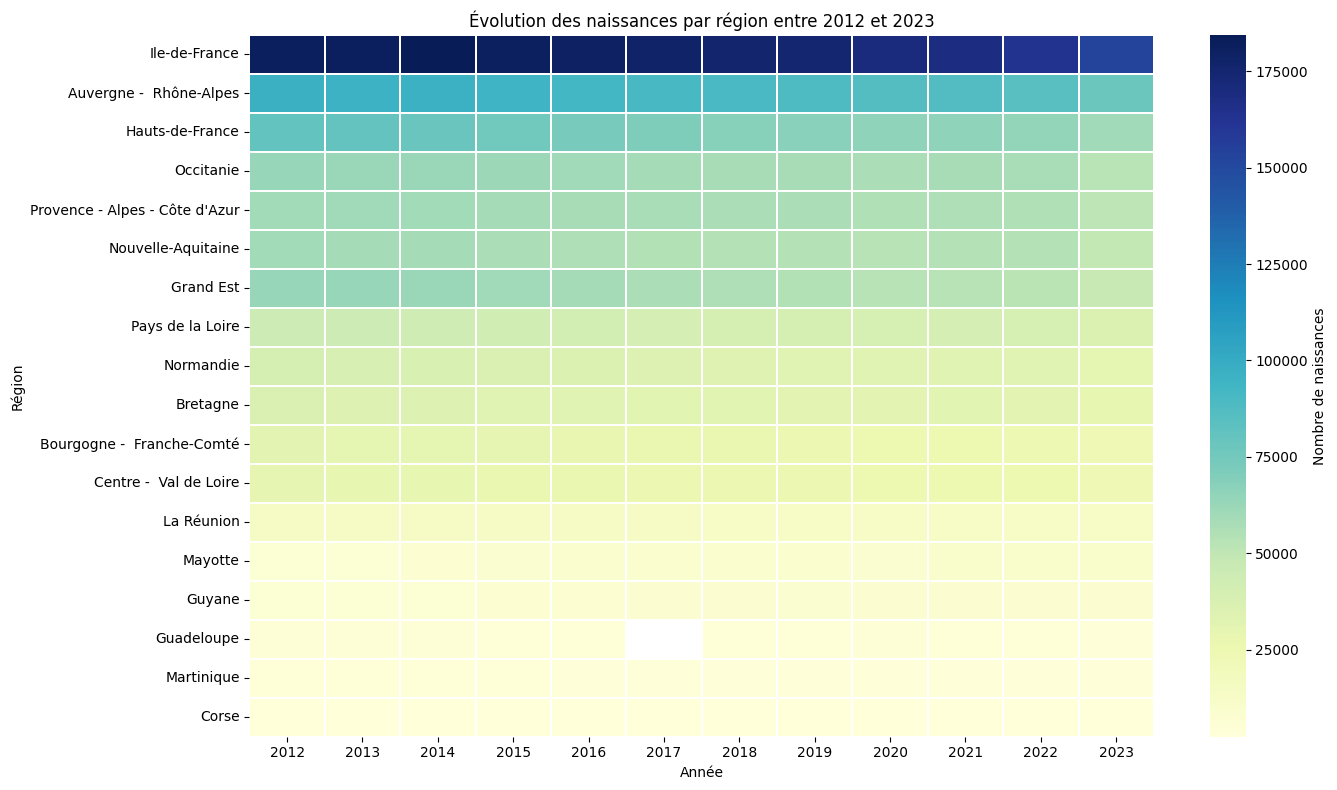

In [29]:
# Colonnes annuelles disponibles dans le DataFrame régional
colonnes_heatmap = sorted(
    [col for col in df_regions.columns if col.endswith("_naissances_totales")],
    key=lambda col: int(col.split("_")[0])
)

# Création de la matrice régions × années
heatmap_naissances = (
    df_regions
    .set_index("zone_géographique")[colonnes_heatmap]
    .apply(pd.to_numeric, errors="coerce")
)

# Remplacement des noms de colonnes par les années
heatmap_naissances.columns = [
    int(col.split("_")[0]) for col in heatmap_naissances.columns
]

# Tri selon la valeur de 2023 pour faciliter la lecture
heatmap_naissances = heatmap_naissances.sort_values(
    by=2023,
    ascending=False
)

# Création de la Heatmap
plt.figure(figsize=(14, 8))

sns.heatmap(
    heatmap_naissances,
    cmap="YlGnBu",
    linewidths=0.3,
    cbar_kws={"label": "Nombre de naissances"}
)

plt.title("Évolution des naissances par région entre 2012 et 2023")
plt.xlabel("Année")
plt.ylabel("Région")
plt.tight_layout()
plt.show()


### Interprétation

Les couleurs les plus intenses se concentrent durablement en Île-de-France, puis dans les grandes régions métropolitaines.  
La diminution progressive de l'intensité vers les dernières colonnes traduit une baisse des naissances dans la majorité des régions.

La Heatmap montre ainsi que la tendance nationale ne dépend pas d'un seul territoire : elle est visible dans une grande partie des régions françaises.


## 3.5 Top 10 des départements en 2023 — barres horizontales Plotly

### Choix de la technique

Un graphique en **barres horizontales** est plus lisible qu'un graphique vertical lorsque les noms des départements sont longs.  
Le tri facilite la comparaison et les étiquettes affichent directement les valeurs.

Plotly permet également d'explorer les données au survol et prépare une intégration simple avec `st.plotly_chart()` dans Streamlit.


In [30]:
# Sélection et tri des dix départements ayant le plus de naissances
top10_departements = (
    df_departements[["zone_géographique", "2023_naissances_totales"]]
    .copy()
    .rename(columns={
        "zone_géographique": "Département",
        "2023_naissances_totales": "Naissances"
    })
)

top10_departements["Naissances"] = pd.to_numeric(
    top10_departements["Naissances"],
    errors="coerce"
)

top10_departements = (
    top10_departements
    .dropna()
    .nlargest(10, "Naissances")
    .sort_values("Naissances", ascending=True)
)

# Création du graphique interactif
fig = px.bar(
    top10_departements,
    x="Naissances",
    y="Département",
    orientation="h",
    color="Naissances",
    text="Naissances",
    title="Top 10 des départements par nombre de naissances en 2023"
)

fig.update_traces(
    texttemplate="%{text:,.0f}",
    textposition="outside",
    hovertemplate="<b>%{y}</b><br>Naissances : %{x:,.0f}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Nombre de naissances",
    yaxis_title="Département",
    coloraxis_showscale=False,
    margin=dict(r=80)
)

fig.update_xaxes(tickformat=",")
fig.show()


### Interprétation

Le Nord arrive en tête du classement, suivi notamment de la Seine-Saint-Denis, des Bouches-du-Rhône et de Paris.  
Plusieurs départements franciliens figurent dans le Top 10, ce qui confirme le poids démographique de l'Île-de-France.

Ce classement repose sur des effectifs bruts. Il identifie les territoires enregistrant le plus de naissances, mais il ne doit pas être interprété comme un taux rapporté à la population.


## Conclusion de l'analyse des naissances

Les différentes visualisations convergent vers trois constats :

1. le nombre de naissances diminue globalement en France entre 2012 et 2023 ;
2. l'Île-de-France reste le principal territoire en volume ;
3. la baisse est visible dans une grande partie des régions.

Le notebook mobilise plusieurs techniques complémentaires : préparation au format long avec Pandas, courbe Matplotlib, Treemap et Area chart Plotly, Heatmap Seaborn et classement interactif. Les objets préparés pourront ensuite être repris dans l'application Streamlit.
